Notebook to motivate the use of multiple cores augmented streamlines

In [1]:
import numpy as np
import matplotlib.pylab as pl
from dipy.io.streamline import load_tractogram
import seaborn as sns
import pandas as pd

from tractot.load_to_numpy import trx_to_numpy_FAT_list,trx_to_numpy_FAT_array,trx_to_numpy_MAT_list,trx_to_numpy_MAT_array
from tractot.distances import distance_MAP

In [2]:
path='/home/gui/Documents/Post-doc/data/PPMI/PD'
subject='100267'
TRACT='CST_right'
n,c=40,30

In [3]:
FAS=load_tractogram(path+"/"+subject+'/06-AugmentedTractsOT/6augmented_FA_nolift_'+TRACT+'_n'+str(n)+'_c'+str(c)+'.trx',
                      reference='same')

MAS=load_tractogram(path+"/"+subject+'/06-AugmentedTractsOT/6augmented_MAS_lift_'+TRACT+'_n'+str(n)+'_c'+str(c)+'.trx',
                      reference='same')

m,FA,_=trx_to_numpy_FAT_array(FAS)
m,wI,I,w,S,_,_=trx_to_numpy_MAT_array(MAS)



In [4]:
cores_FAS_L1=load_tractogram(path+"/"+subject+'/06-AugmentedTractsOT/7cores_FA_nolift_'+TRACT+'_L1_k1.trx',
                      reference='same')
cores_FAS_L10=load_tractogram(path+"/"+subject+'/06-AugmentedTractsOT/7cores_FA_nolift_'+TRACT+'_L10_k1.trx',
                      reference='same')

cores_MAS_L1=load_tractogram(path+"/"+subject+'/06-AugmentedTractsOT/7cores_MAS_lift_'+TRACT+'_L1_kNone.trx',
                      reference='same')
cores_MAS_L10=load_tractogram(path+"/"+subject+'/06-AugmentedTractsOT/7cores_MAS_lift_'+TRACT+'_L10_kNone.trx',
                      reference='same')

_,_,FA_core_1,labels_svm_FA1,_=trx_to_numpy_FAT_list(cores_FAS_L1)
_,_,FA_core_10,labels_svm_FA10,_=trx_to_numpy_FAT_list(cores_FAS_L10)

m_core_1,wI_core_1,I_core_1,w_core_1,S_core_1,labels_svm_MAS1,_=trx_to_numpy_MAT_list(cores_MAS_L1)
m_core_10,wI_core_10,I_core_10,w_core_10,S_core_10,labels_svm_MAS10,_=trx_to_numpy_MAT_list(cores_MAS_L10)

In [24]:
idx_antecedent_FA1=cores_FAS_L1.data_per_point['antecedent']
idx_antecedent_FA10=cores_FAS_L10.data_per_point['antecedent']

idx_antecedent_MAS1=cores_MAS_L1.data_per_point['antecedent']
idx_antecedent_MAS10=cores_MAS_L10.data_per_point['antecedent']

# FAS
Compare the averaged FAP of the core(s) with the inital set of FAP. When we consider only one core, the average can be not representative of the set. 

In [122]:
res_FA1=[]
for j in range(40):
    res_FA1+=[[]]
    
for j,idx in enumerate(np.int8(labels_svm_FA1[0])):
    res_FA1[idx-1]=FA_core_1[0][j]

res_FA10=[]
for i in range(10):
    res_FA10+=[[]]
    for j in range(40):
        res_FA10[i]+=[[]]

for i in range(10):
    for j,idx in enumerate(np.int8(labels_svm_FA10[i])):
        res_FA10[i][idx-1]=FA_core_10[i][j]


FA_ante_1=[]
for j in range(40):
        FA_ante_1+=[[]]

for j,idx in enumerate(np.int8(labels_svm_FA1[0])):
    FA_ante_1[idx-1]=FA[(idx_antecedent_FA1[0][j]).reshape(-1,40)]

FA_ante_10=[]
for i in range(10):
    FA_ante_10+=[[]]
    for j in range(40):
        FA_ante_10[i]+=[[]]

for i in range(10):
    for j,idx in enumerate(np.int8(labels_svm_FA10[i])):
        FA_ante_10[i][idx-1]=FA[(idx_antecedent_FA10[i][j]).reshape(-1,40)]

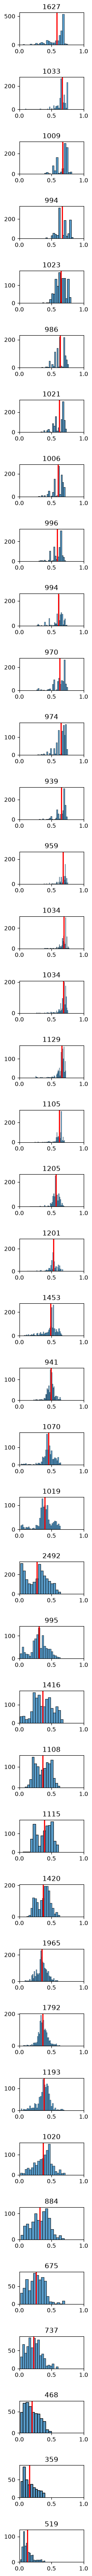

In [123]:
pl.figure(figsize=(2,80))
grid = pl.GridSpec(40,1, wspace=0.1, hspace=1)
for j in np.int8(labels_svm_FA1[0]):
    a=pd.DataFrame(FA_ante_1[j-1],columns=['FA'])
    
    pl.subplot(grid[j-1,0])
    sns.histplot(data=a,x='FA',stat='count',legend=False,color='C0')#,kde=True,binrange=(0,0.002))
    pl.axvline(x = res_FA1[j-1], color = 'r',linewidth=2)

    pl.xlabel("")
    pl.ylabel("")
    pl.xlim(0,1)
    pl.title(FA_ante_1[j-1].shape[0])

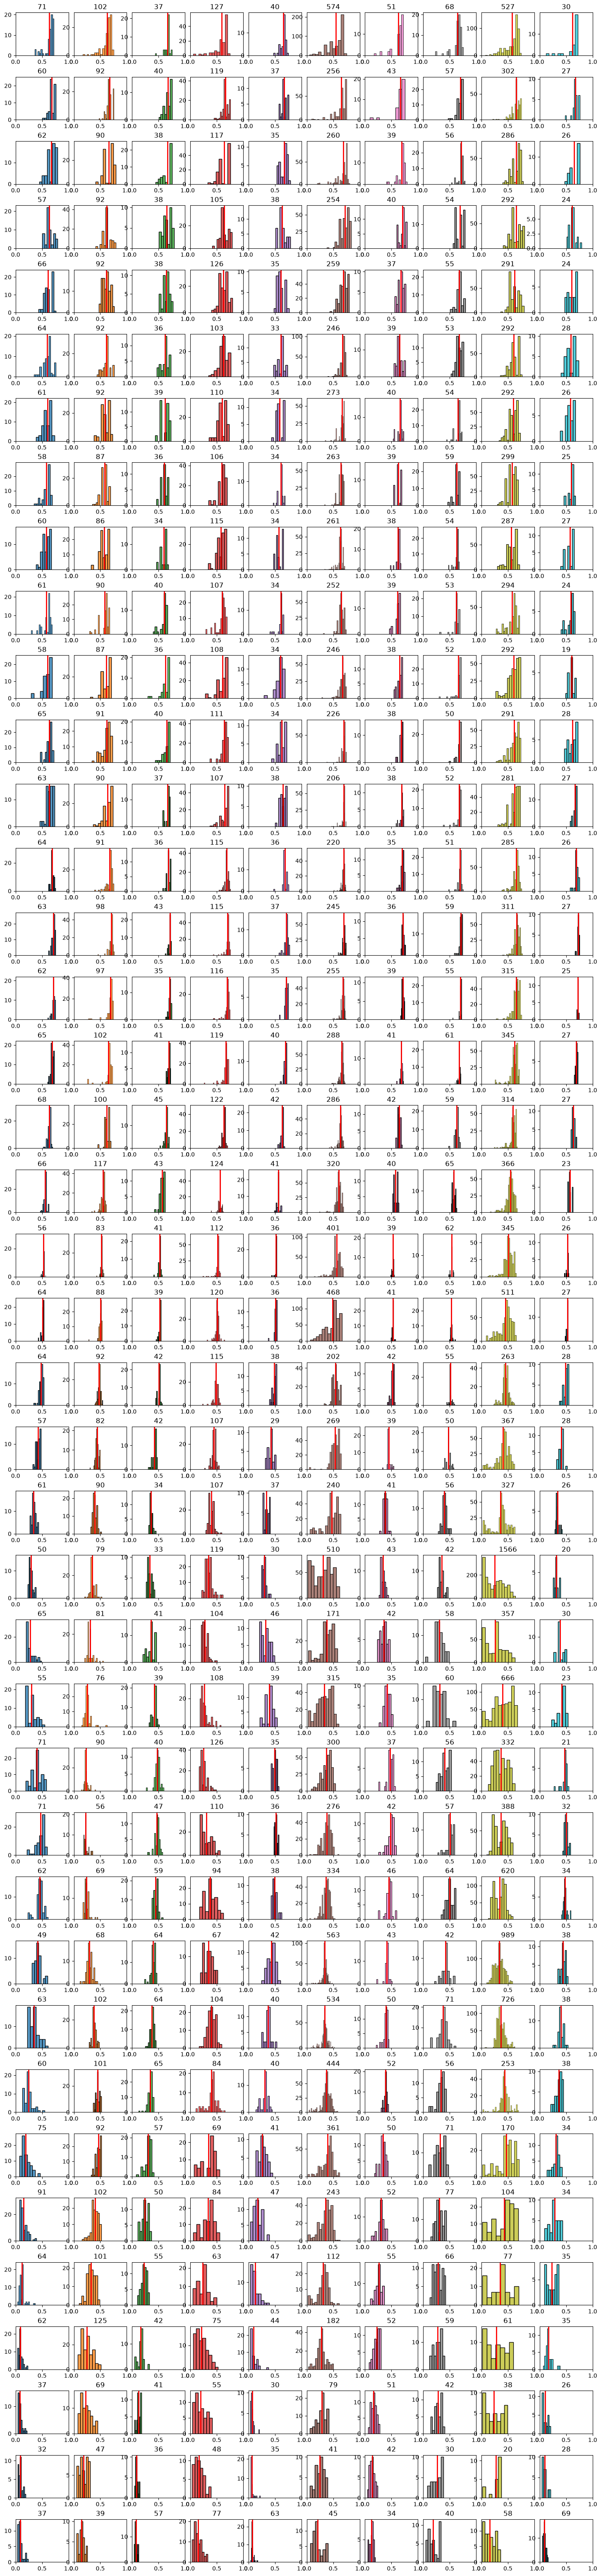

In [124]:
pl.figure(figsize=(18,80))
grid = pl.GridSpec(40,10, wspace=0.1, hspace=0.5)
for i in range(10):
    for j in np.int8(labels_svm_FA10[i]):
        a=pd.DataFrame(FA_ante_10[i][j-1],columns=['FA'])
        
        pl.subplot(grid[j-1,i])
        sns.histplot(data=a,x='FA',color='C%i'%i,stat='count',legend=False)
        pl.axvline(x = res_FA10[i][j-1], color = 'r',linewidth=2)
        pl.xlabel("")
        pl.ylabel("")
        pl.xlim(0,1)
        pl.title(FA_ante_10[i][j-1].shape[0])

# MAS
Compare the distance between the averaged MAP of the core(s) with the inital set of MAPs. When we consider only one core, the average can be not representative of the set. 

In [125]:
res_MAS1=[]
for j in range(40):
    res_MAS1+=[[]]
  
for j,idx in enumerate(np.int8(labels_svm_MAS1[0])):
    m_j=m[(idx_antecedent_MAS1[0][j]).reshape(-1,40)]
    wI_j=wI[(idx_antecedent_MAS1[0][j]).reshape(-1,40)]
    I_j=I[(idx_antecedent_MAS1[0][j]).reshape(-1,40)]
    w_j=w[(idx_antecedent_MAS1[0][j]).reshape(-1,40)]
    S_j=S[(idx_antecedent_MAS1[0][j]).reshape(-1,40)]

    res_MAS1[idx-1]=np.zeros(m_j.shape[0])
    for k in range(m_j.shape[0]):
        res_MAS1[idx-1][k]=distance_MAP(m_j[k],m_core_1[0][j],
                                                             wI_j[k],wI_core_1[0][j],
                                                             I_j[k],I_core_1[0][j],
                                                             w_j[k],w_core_1[0][j],
                                                             S_j[k],S_core_1[0][j],alpha=0)


res_MAS10=[]
for i in range(10):
    res_MAS10+=[[]]
    for j in range(40):
        res_MAS10[i]+=[[]]

for i in range(10):
    for j,idx in enumerate(np.int8(labels_svm_MAS10[i])):
        m_j=m[(idx_antecedent_MAS10[i][j]).reshape(-1,40)]
        wI_j=wI[(idx_antecedent_MAS10[i][j]).reshape(-1,40)]
        I_j=I[(idx_antecedent_MAS10[i][j]).reshape(-1,40)]
        w_j=w[(idx_antecedent_MAS10[i][j]).reshape(-1,40)]
        S_j=S[(idx_antecedent_MAS10[i][j]).reshape(-1,40)]
        
        res_MAS10[i][idx-1]=np.zeros(m_j.shape[0])
        for k in range(m_j.shape[0]):
            res_MAS10[i][idx-1][k]=distance_MAP(m_j[k],m_core_10[i][j],
                                                                 wI_j[k],wI_core_10[i][j],
                                                                 I_j[k],I_core_10[i][j],
                                                                 w_j[k],w_core_10[i][j],
                                                                 S_j[k],S_core_10[i][j],alpha=0)

In [141]:
suum=0
for j in range(40):
    suum+=np.sum(res_MAS1[j])  

suum

np.float64(7.932264163692921)

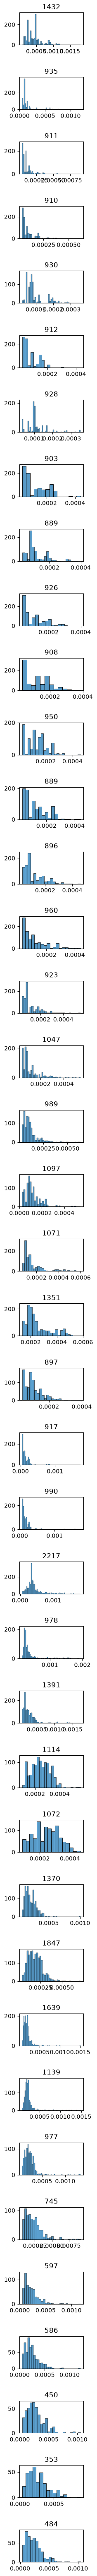

In [131]:
pl.figure(figsize=(2,80))
grid = pl.GridSpec(40,1, wspace=0.1, hspace=1)
for j in np.int8(labels_svm_MAS1[0]):
    a=pd.DataFrame(res_MAS1[j-1],columns=['distance'])
    
    pl.subplot(grid[j-1,0])
    sns.histplot(data=a,x='distance',stat='count',legend=False,color='C0')#,kde=True,binrange=(0,0.002))

    pl.xlabel("")
    pl.ylabel("")
    pl.title(res_MAS1[j-1].shape[0])

In [140]:
suum=0
for i in range(10):
    for j in range(40):
        suum+=np.sum(res_MAS10[i][j])  

suum

np.float64(6.594701223746467)

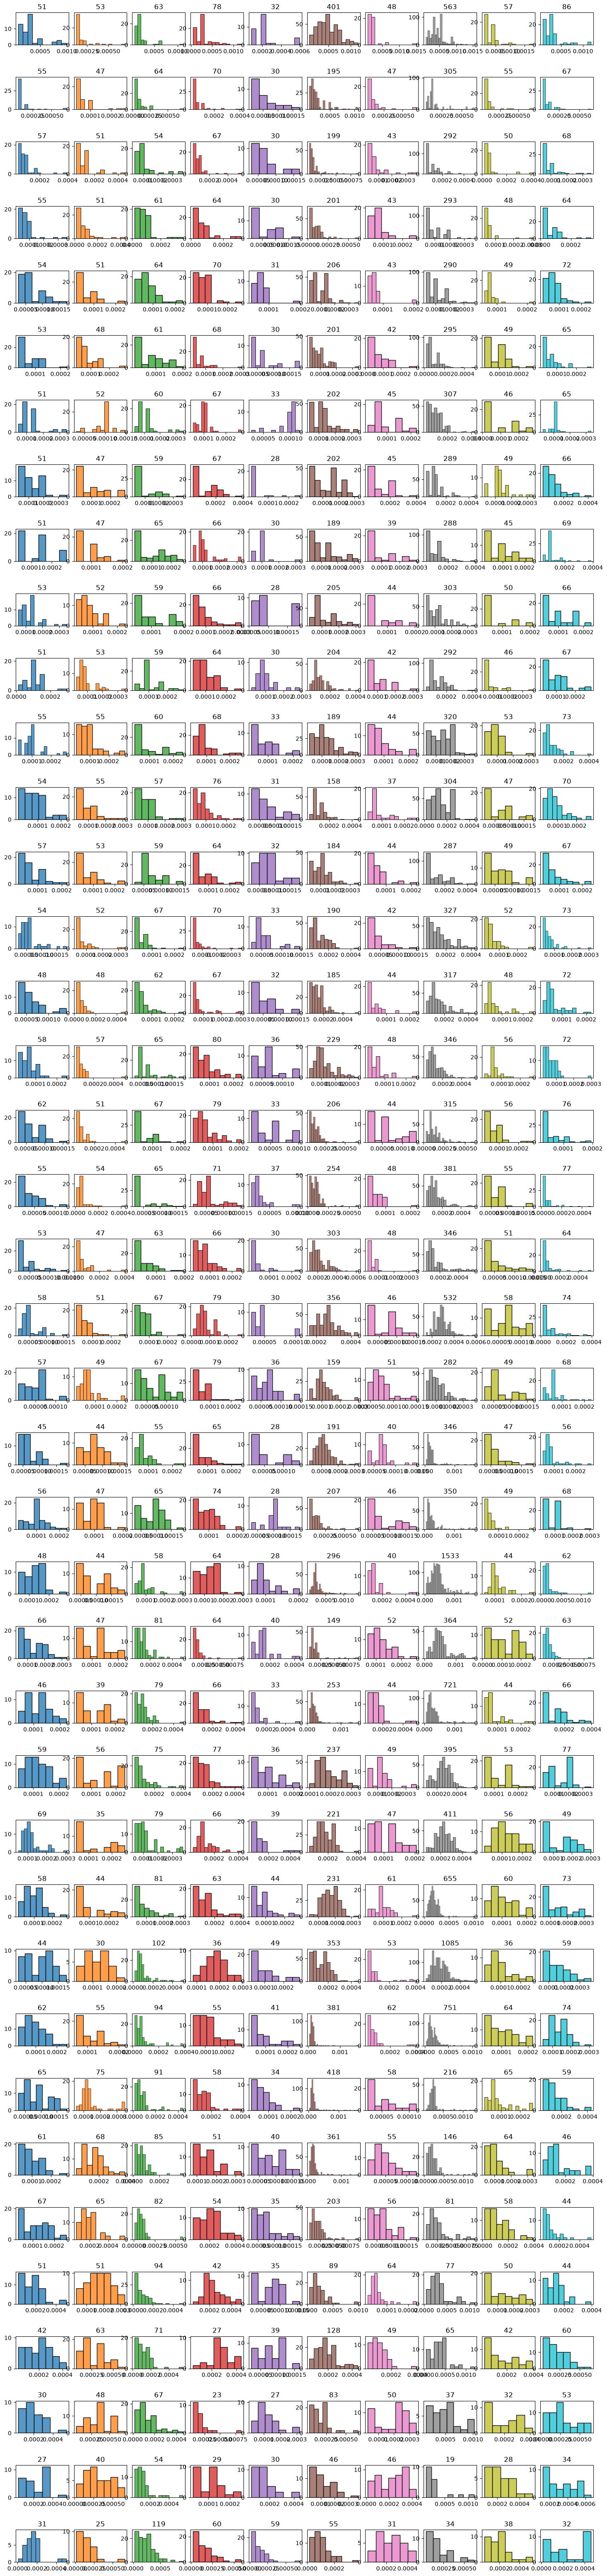

In [138]:
pl.figure(figsize=(18,80))
grid = pl.GridSpec(40,10, wspace=0.1, hspace=1)
for i in range(10):
    for j in np.int8(labels_svm_FA10[i]):
        a=pd.DataFrame(res_MAS10[i][j-1],columns=['distance'])
        
        pl.subplot(grid[j-1,i])
        sns.histplot(data=a,x='distance',color='C%i'%i,stat='count',legend=False)
        pl.xlabel("")
        pl.ylabel("")
        pl.title(res_MAS10[i][j-1].shape[0])